In [1]:
import baltic as bt
import pandas as pd
import json
import os
import matplotlib as mpl
from matplotlib import pyplot as plt
import requests
from io import StringIO as sio
from matplotlib.patches import Patch
import matplotlib.ticker as ticker
import itertools
import re
import sys
import pprint
import statistics

In [2]:
def load_tree(nexusPath):
    mytree = bt.loadNexus(nexusPath, tip_regex='\|([0-9]{4}\-[0-9]{2}\-[0-9]{2})', absoluteTime=True, verbose=False) # your tip regex might have to change or you could convert you tree into a newick by deleting everything before the tree string lol
    return(mytree)

In [3]:
# Load tree
#nexusPath=f'./BEAST/continuous_phylogeography/results/2025-07-10_nov2021-2024_ha_contphyl_thorney/NAm_wild-aves_nov2021-2024_ha_contphyl_2025-07-10_MCC.tree' # your path here
#nexusPath_1='./BEAST/continuous_phylogeography/results/2025-08-20_nov2021-2024_no-suliformes_ha_contphyl_thorney_redo/NAm_wild-aves_nov2021-2024_no-suliformes_ha_contphyl_2025-08-18_MCC.tree' 
#nexusPath_2 = "./BEAST/discrete_trait_analysis/results/2025-09-01_flyway-latitude-order_emptree-contphyl/NAm_wild-aves_nov2021-2024_no-suliformes_ha_emptree-contphyl_flyway-order-latgrp_MCC.tree"
#nexusPath_3 = "./BEAST/empirical_trees/results/2025-08-07_nov2021-2024_no-suliformes_ha_empirical_thorney/NAm_wild-aves_nov2021-2024_no-suliformes_ha_empirical_thorney_2025-08-11_MCC.tree"
# nexusPath = "../H5N5-mini-project/SERAPHIM/A6_concat_genome_skyride_DTA-contphyl_2026-01-06_MCC.tree"
# nexusPath = "../H5N5-mini-project/SERAPHIM/test.tree"
# nexusPath = "./Nextstrain/2025-12-22_NAm_aves-wild_contextual-no-SAm_county-priority/time-tree_main-introduction.nwk"
# nexusPath = "../H5N5-mini-project/SERAPHIM/A6_concat-genome_traits_2026-03-01_MCC_renamed.tree"
nexusPath = "../H5N5-mini-project/SERAPHIM/A6_concat-genome_traits_2026-03-10_MCC.tree"

In [4]:
# Load continuous phylogeography tree
# contphyltree = load_tree(nexusPath_1)
# Load DTA tree
#dtatree = load_tree(nexusPath_2)
# Load Empirical tree
#emptree = load_tree(nexusPath_3)
tree = load_tree(nexusPath)

In [52]:
tree = bt.loadNewick("./Nextstrain/2025-08-06_NAm_aves-wild_contextual-no-SAm_no-suliformes-clade_county-priority/nextstrain_time-tree_NAm-outbreak.nwk", absoluteTime = True, verbose = False)

In [5]:
# Now many nodes and leaves is your tree

# print(len(contphyltree.Objects))
# print(len(dtatree.Objects))
# print(len(emptree.Objects))

# contphyltree.treeStats()
# dtatree.treeStats()
# emptree.treeStats()

print(len(tree.Objects))
tree.treeStats()

665

Tree height: 4.511821
Tree length: 102.563445
strictly bifurcating tree
annotations present

Numbers of objects in tree: 665 (332 nodes and 333 leaves)



In [13]:
# What objects are included in the tree

#print(dir(tree.Objects[0].traits))
i = 0
for k in tree.Objects:
    if k.is_node():
        i+=1
        name = f"{i}_node"
        k.name = name

for k in tree.Objects:
    if k.name == "EPI_ISL_18901717|A/White-tailed_eagle/Norway/2022-07-1141-5/2022|H5N5|Europe|2022-06-15|wild_avian|A6":
        print(k.traits.keys())
    

dict_keys(['host.rate_median', 'region.prob', 'location2_positiveProb', 'location1_positiveProb', 'location.rate_median', 'height_median', 'location.rate', 'length_median', 'height', 'location2_median', 'location1_median', 'length', 'region.rate_median', 'host.rate', 'region', 'host.prob', 'location1', 'region.rate', 'location2', 'host', 'length_range', 'height_range', 'host.rate_range', 'location.rate_signDistribution', 'host.set.prob', 'location1_range', 'host.rate_signDistribution', 'region.rate_range', 'region.rate_signDistribution', 'length_signDistribution', 'region.set.prob', 'location2_range', 'height_signDistribution', 'location1_80%HPD_3', 'location1_80%HPD_2', 'location1_80%HPD_1', 'length_95%_HPD', 'host.set', 'height_95%_HPD', 'location.rate_95%_HPD', 'host.rate_95%_HPD', 'location2_80%HPD_1', 'location2_80%HPD_2', 'location2_80%HPD_3', 'region.set', 'region.rate_95%_HPD', 'location.rate_range'])


In [8]:
# This allows me to explore the tree a bit
# Change k.index and k, 'parent' to explore the objects for each item

for k in mytree2.Objects[:3]:
    print(f"{k.index}: {getattr(k, 'is_node')}")

NameError: name 'mytree2' is not defined

In [130]:
# TipMap is a list of tip names and their associated numbers
print(type(mytree2.tipMap))

<class 'dict'>


In [133]:
# This prints all of the leaf names in the tree

# for k in mytree2.getExternal(): ## iterate through leaf objects in tree
#     print(k.name)

In [8]:
# Set a flyway attribute for each leaf

# Turn tipMap into a dataframe
tipMap_df = pd.DataFrame.from_dict(contphyltree.tipMap, orient='index', columns=['leaf_name'])
#tipMap_df = pd.DataFrame.from_dict(dtatree.tipMap, orient='index', columns=['leaf_name'])
#tipMap_df = pd.DataFrame.from_dict(emptree.tipMap, orient='index', columns=['leaf_name'])
print(len(tipMap_df))

# Add a column for flyway
tipMap_df_upt = tipMap_df.copy()
tipMap_df_upt["NAflyway"] = tipMap_df_upt["leaf_name"].str.split("|", expand = True)[4]
print(tipMap_df_upt["NAflyway"].value_counts())

# Turn tipMap_df_upt back into a dictionary
tipMap_upt = tipMap_df_upt.to_dict(orient='index')

# Switch around the dictionary
name_to_flyway = {v['leaf_name']: v['NAflyway'] for v in tipMap_upt.values()}

NameError: name 'contphyltree' is not defined

In [36]:
# Set a flyway attribute for each leaf

# Turn tipMap into a dataframe
# tipMap_df = pd.DataFrame.from_dict(conphyltree.tipMap, orient='index', columns=['leaf_name'])
#tipMap_df = pd.DataFrame.from_dict(dtatree.tipMap, orient='index', columns=['leaf_name'])
#tipMap_df = pd.DataFrame.from_dict(emptree.tipMap, orient='index', columns=['leaf_name'])
# tipMap_df = pd.DataFrame.from_dict(conphyltree.tipMap, orient='index', columns=['leaf_name'])

tipnames = []

for k in tree.Objects:
    if k.is_leaf():
        tipnames.append(k.name)

tipMap_df = pd.DataFrame(tipnames).rename({0:"leaf_name"}, axis = 1)

print(len(tipMap_df))

# Add a column for flyway
tipMap_df_upt = tipMap_df.copy()
# tipMap_df_upt["bird_species"] = tipMap_df_upt["leaf_name"].str.split("|", expand = True)[0].str.split("/", expand = True)[1]

# birdies = pd.read_csv("./metadata/helpful_lists/NAm_host_list_order-domesticstat.csv", sep = ",", encoding='latin-1')
# birdies_dict = birdies.set_index("strain_host").to_dict(orient="index")
# tipMap_df_upt["bird_group"] = tipMap_df_upt["bird_species"].map(lambda host: birdies_dict.get(host, {}).get("host_group2"))

# print(tipMap_df_upt["bird_group"].value_counts())

tipMap_df_upt["flyway"] = tipMap_df_upt["leaf_name"].str.split("|", expand = True)[4]

# # Turn tipMap_df_upt back into a dictionary
tipMap_upt = tipMap_df_upt.to_dict(orient='index')

# Switch around the dictionary
name_to_flyway = {v['leaf_name']: v['flyway'] for v in tipMap_upt.values()}

5498


In [7]:
#Test that tree is loaded
# for k in mytree.Objects:
    # if k.name == "NODE_0004247":
    #     print(k.traits)
        
    # # Use get() at each level to avoid KeyErrors if any key is missing
    # value = k.traits.get("node_attrs", {}).get("NAflyway", {}).get("value")
    # #value = k.traits.get("node_attrs", {}).get("bird_order", {}).get("value")
    
    # # Check if value is ever "unknown"
    # if not value:
    #     print(k.name)

In [29]:
flyway_colors = {
    "AtlanticFlyway":"#AA7722",
    "MississippiFlyway":"#5E9B82",
    "CentralFlyway":"#C593D1",
    "PacificFlyway":"#2B57B3"
}

In [39]:
flyway_colors = {"accipitriformes":"#C593D1",
               "strigiformes":"#C593D1", 
               "anseriformes":"#2B57B3",
               "charadriiformes":"#AA7722",
               "pelecaniformes":"#AA7722",
               "passeriformes":"#5E9B82",
               "falconiformes":"#5E9B82",
               "suliformes":"#5E9B82",
               "podicipediformes":"#5E9B82",
               "galliformes":"#5E9B82",
               "columbiformes":"#5E9B82",
               "gruiformes":"#5E9B82",
               "gaviiformes":"#5E9B82",
               "ciconiiformes":"#5E9B82",
               "apodiformes":"#5E9B82",
               "unknown":"#5E9B82",
               "casuariiformes":"#5E9B82",
               "other":"#5E9B82"
              }

In [11]:
colors = {"seab":"#6AA1F4",
          "bdpr":"#F69BA6",
          "gds":"#6A994E",
          "mammal":"#A874D2",
          "scav":"#923E4D",
          "grdbd":"#E9C46A"
 #         "other":"#95A8B0"
         }

host_group_colors = {"bird-of-prey":"#C43110", # red-maroon
                     "duck":"#679C48", # green 
                     "goose-swan": "#DBB730", # yellow
                     "shorebird":"#68A0A6", # blue
                     "songbird-etc":"#D9A7B0", # pink
                     "ground-bird":"#E08907", # orange
                     "diving-bird":"#503A63", # deep purple
                     "other":"#A0A0A3" # grey
                    }

In [38]:
colors = {"europe":"#ffaaaa",
          "east-canada":"#95b8d1",
          "new-england":"#f7df7d",
          "north-canada":"#ba9cc9",
          "pacific-northwest":"#94bf73",
          "asia":"#b09a6e"
         }

In [39]:
# labels = {"seab":"Seabirds and Shorebirds",
#           "bdpr":"Birds of Prey",
#           "gds":"Geese, ducks, and seaducks",
#           "mammal":"Mammals",
#           "scav":"Scavengers",
#           "grdbd":"Ground birds"
 #         "other":"#95A8B0"
         # }

labels = {"europe":"Europe",
          "east-canada":"Eastern Canada",
          "new-england":"New England",
          "north-canada":"Northern Canada",
          "pacific-northwest":"Pacific Northwest (USA)",
          "asia":"Asia"
         }

In [40]:
def plot_nexus(mytree, save_path):

    plt.rcParams["font.family"] = "Arial"

    fig,ax = plt.subplots(figsize=(10,20),facecolor='w')
    
    #kwargs={'size': 20} ## kwargs for text
    
    x_attr=lambda k: k.absoluteTime
    
    # print(k)
        
    # Set the color-by (old function)
    # default color D1E2F0                                 
    def color_by(k):
        # flyway = tipMap_upt.get(k.index, {}).get("NAflyway")
        # order = k.traits["host"]
        region = k.traits["region"]
        return colors.get(region, "#D1E2F0")

    # for k in mytree.getExternal(): # Extract the flyway for each tip name using the name_to_flyway dictionary
    #     flyway = name_to_flyway.get(k.name, None)  # None if no match
    #     k.flyway = flyway

    # def color_by(k): # Color-by function for cont phyl (not a DTA, so I can only color the tips because only the locations of nodes are inferred)
    #     if hasattr(k, 'flyway') and k.flyway in flyway_colors:
    #         return flyway_colors[k.flyway]
    #     return '#898989'  # default color
    
    mytree.plotTree(ax,x_attr=x_attr, colour=color_by) ## tree
    mytree.plotPoints(ax,
                      x_attr=x_attr,
                      size=30,
                      colour=color_by,
                      zorder=100)
    ax.plot() ## need to call plot when only drawing the tree to force drawing of line collections

    # # # If you want tree annotations
    # # # target_func=lambda k: k.is_leaf() ## which branches will be annotated
    # # # text_func=lambda k: k.traits['rea'] if k.traits['is_reassorted'] else "" ## what text is plotted
    # # # text_x_attr=lambda k: k.x+0.003 ## where x coordinate for text is
    # # # mytree.addText(ax,x_attr=text_x_attr,target=target_func,text=text_func, size='10')

    # If you want the legend in the tree
    #legend_handles = [Patch(color=color, label=labels[order]) for order, color in colors.items()]
    #legend = ax.legend(handles=legend_handles, title="$\\bf{Host Group}$", loc="lower left", fontsize='15')
    #plt.setp(legend.get_title(),fontsize=25)

    # # # If you want a scale bar
    # # # scale_length = 0.01
    # # # x_min, x_max = ax.get_xlim()
    # # # scale_x_start = x_min + (x_max - x_min) * 0.1
    # # # scale_x_end = scale_x_start + scale_length * (x_max - x_min)
    # # # scale_y = 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0]) + ax.get_ylim()[0]
    
    # ax.plot([scale_x_start, scale_x_end], [scale_y, scale_y], color='black', lw=2)
    # ax.text((scale_x_start + scale_x_end) / 2, scale_y, f'{scale_length}', 
    #         ha='center', va='bottom', fontsize=15)
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    [ax.spines[loc].set_visible(False) for loc in ax.spines if loc not in ['bottom']]
    ax.tick_params(axis='x',labelsize=20,size=15, width=2,color='grey')
    fig.tight_layout()
    plt.savefig(save_path)
    plt.show()

In [21]:
# plot_nexus(contphyltree, "./BEAST/continuous_phylogeography/results/2025-08-20_nov2021-2024_no-suliformes_ha_contphyl_thorney_redo/NAm_wild-aves_nov2021-2024_no-suliformes_ha_contphyl_2025-08-18_MCC-baltic_althostcolors.pdf")

In [22]:
# plot_nexus(dtatree, "./BEAST/discrete_trait_analysis/results/2025-09-01_flyway-latitude-order_emptree-contphyl/NAm_wild-aves_nov2021-2024_no-suliformes_ha_flyway-order-latgrp_2025-09-01_MCC-baltic.pdf")

In [23]:
# plot_nexus(emptree, "./BEAST/empirical_trees/results/2025-08-07_nov2021-2024_no-suliformes_ha_empirical_thorney/NAm_wild-aves_nov2021-2024_no-suliformes_ha_empirical_thorney_2025-08-07_MCC.pdf")

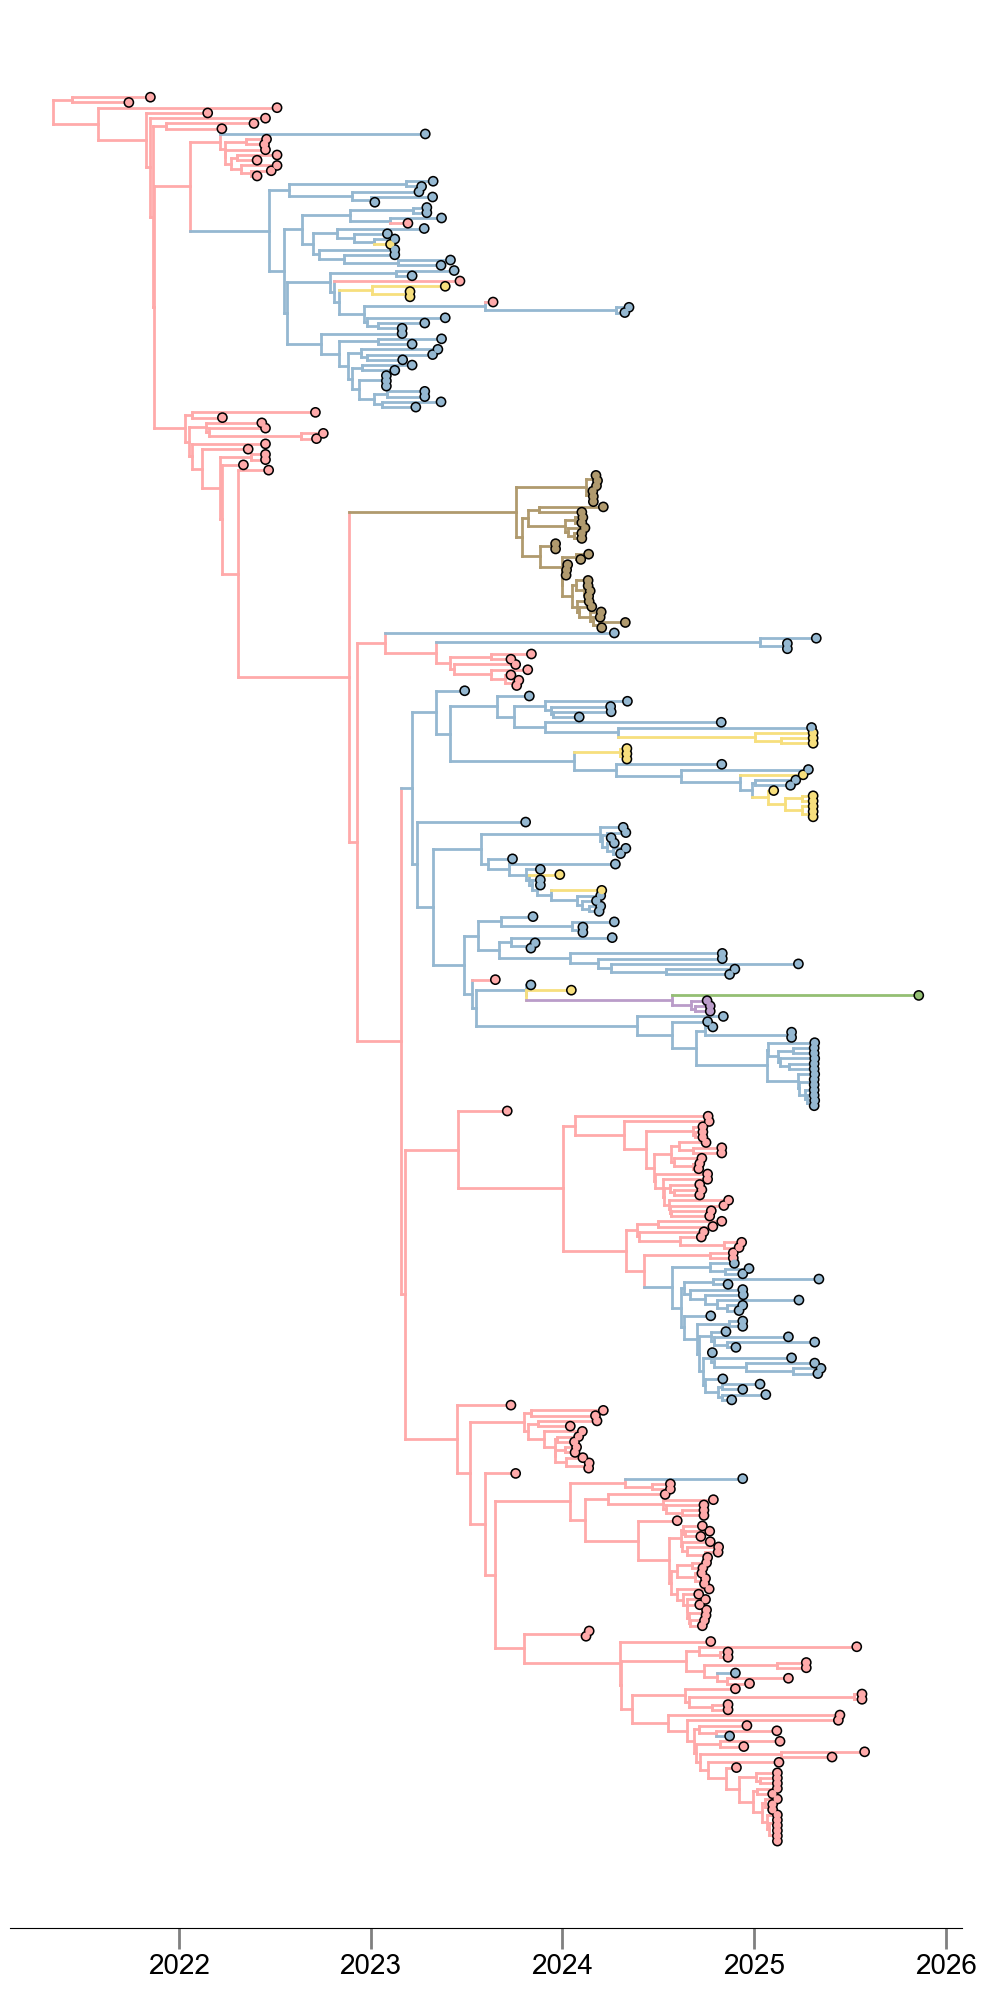

In [41]:
plot_nexus(tree, "../H5N5-mini-project/SERAPHIM/output_plots/baltic_A6_concat-genome_traits_2026-03-10_region.pdf")

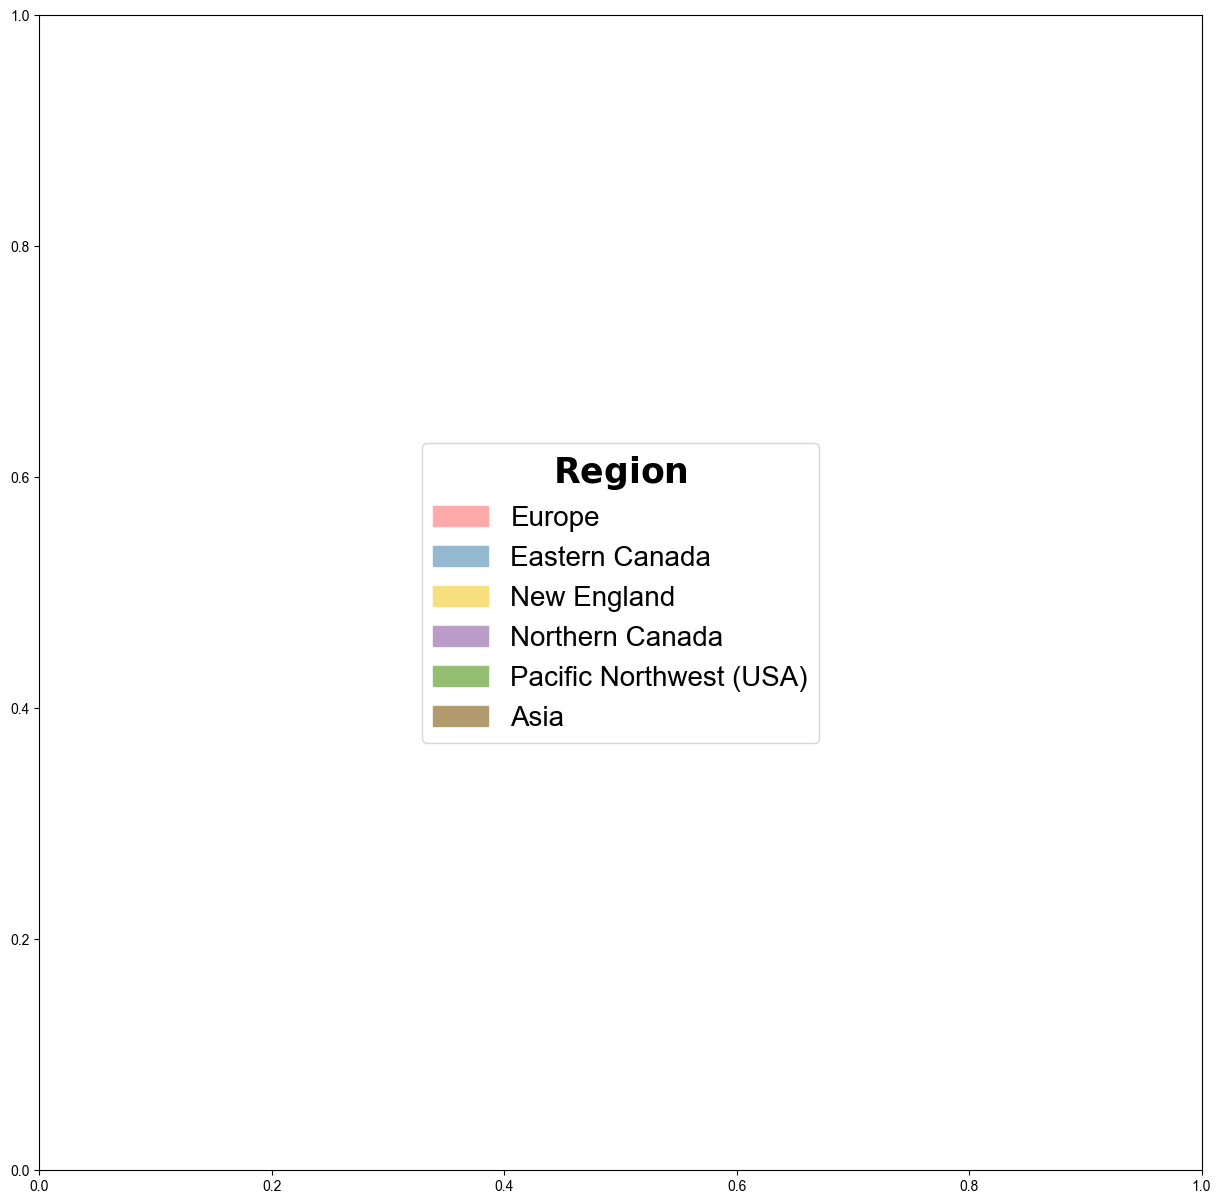

In [42]:
# If you want a separate legend

fig, ax = plt.subplots(figsize=(15, 15))

legend_handles = [Patch(color=color, label=labels[region]) for region, color in colors.items()]
legend = ax.legend(handles=legend_handles, title="$\\bf{Region}$", loc="center", fontsize='20')
plt.setp(legend.get_title(),fontsize=25)

plt.savefig("../H5N5-mini-project/SERAPHIM/output_plots/region_legend.pdf")
plt.show()

In [ ]:
# Plot number of transitions in a DTA